# Network Science: Wikipedia Voting Network Analysis

**Dataset:** [Stanford SNAP — Wikipedia Vote Network](https://snap.stanford.edu/data/wiki-Vote.html)  
**Description:** Directed graph of Wikipedia adminship elections. Each directed edge u→v means user u voted for user v.  
**Tools:** NetworkX · NumPy · Matplotlib · SciPy

---

## Project Structure

| Part | Topic |
|---|---|
| **1** | Structural Analysis — components, degree distributions, centrality |
| **2** | Random Graph Phase Transitions — G(N,p) vs G(N,L) |
| **3** | Biased Random Walk Sampling |
| **4** | Community Detection — Girvan-Newman |
| **5** | Failure Propagation Model |
| **6** | 3-Opinion Voter Model |
| **7** | Min-Cost Max-Flow Optimisation |

---


## Setup — Imports & Global Seed

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import scipy.stats as stats
from collections import Counter
from itertools import islice
from networkx.algorithms.community import girvan_newman, modularity

# ── Global reproducibility ──────────────────────────────────────────────────
SEED = 240401328
rng  = np.random.default_rng(SEED)      # single Generator; avoids legacy np.random.seed
np.random.seed(SEED)                    # kept for NetworkX routines that use the global state

# ── Plot style ───────────────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi":        120,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.grid":         True,
    "grid.alpha":        0.35,
    "font.size":         11,
})
print("Setup complete.")


Setup complete.


---
## Part 1 — Structural Analysis of the Wikipedia Voting Network

### 1a · Nodes, Edges & Connected Components

**Network:** Wikipedia adminship elections — 7,115 users, 103,689 directed votes.


In [2]:
# ── Load the directed graph ──────────────────────────────────────────────────
G = nx.read_edgelist("wikivote.txt", create_using=nx.DiGraph())

num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()

# ── Strongly & weakly connected components ──────────────────────────────────
scc_list = list(nx.strongly_connected_components(G))
wcc_list = list(nx.weakly_connected_components(G))

scc_sizes = sorted([len(c) for c in scc_list], reverse=True)
wcc_sizes = sorted([len(c) for c in wcc_list], reverse=True)

scc_freq = Counter(scc_sizes)
wcc_freq = Counter(wcc_sizes)

print("=" * 50)
print(f"  Nodes  : {num_nodes:,}")
print(f"  Edges  : {num_edges:,}")
print(f"  SCCs   : {len(scc_list):,}  (largest: {scc_sizes[0]:,} nodes)")
print(f"  WCCs   : {len(wcc_list):,}  (largest: {wcc_sizes[0]:,} nodes)")
print("=" * 50)

# ── Size distributions (tabular — plots not informative here) ────────────────
print("\nSCC size distribution (size: count):")
for size, count in sorted(scc_freq.items()):
    print(f"  size {size:>5}: {count:>5} component(s)")

print("\nWCC size distribution (size: count):")
for size, count in sorted(wcc_freq.items()):
    print(f"  size {size:>5}: {count:>5} component(s)")


  Nodes  : 7,115
  Edges  : 103,689
  SCCs   : 5,816  (largest: 1,300 nodes)
  WCCs   : 24  (largest: 7,066 nodes)

SCC size distribution (size: count):
  size     1:  5815 component(s)
  size  1300:     1 component(s)

WCC size distribution (size: count):
  size     2:    20 component(s)
  size     3:     3 component(s)
  size  7066:     1 component(s)


**Interpretation:**

- **SCCs:** 5,816 components; 5,810 are singletons and there is one large SCC of ~1,300 nodes. This directly reflects the nature of Wikipedia voting: votes are largely unidirectional (A votes for B rarely implies B votes for A), so mutual vote cycles — required for membership in a non-trivial SCC — are rare. Only ~18% of nodes participate in reciprocal voting chains.

- **WCCs:** 24 components with one dominant WCC of ~7,066 nodes (99.3% of the network). Ignoring direction, virtually the entire community is reachable through vote chains, consistent with a centralised election system where all voters are loosely connected even without direct mutual votes.


### 1b · Degree Distributions

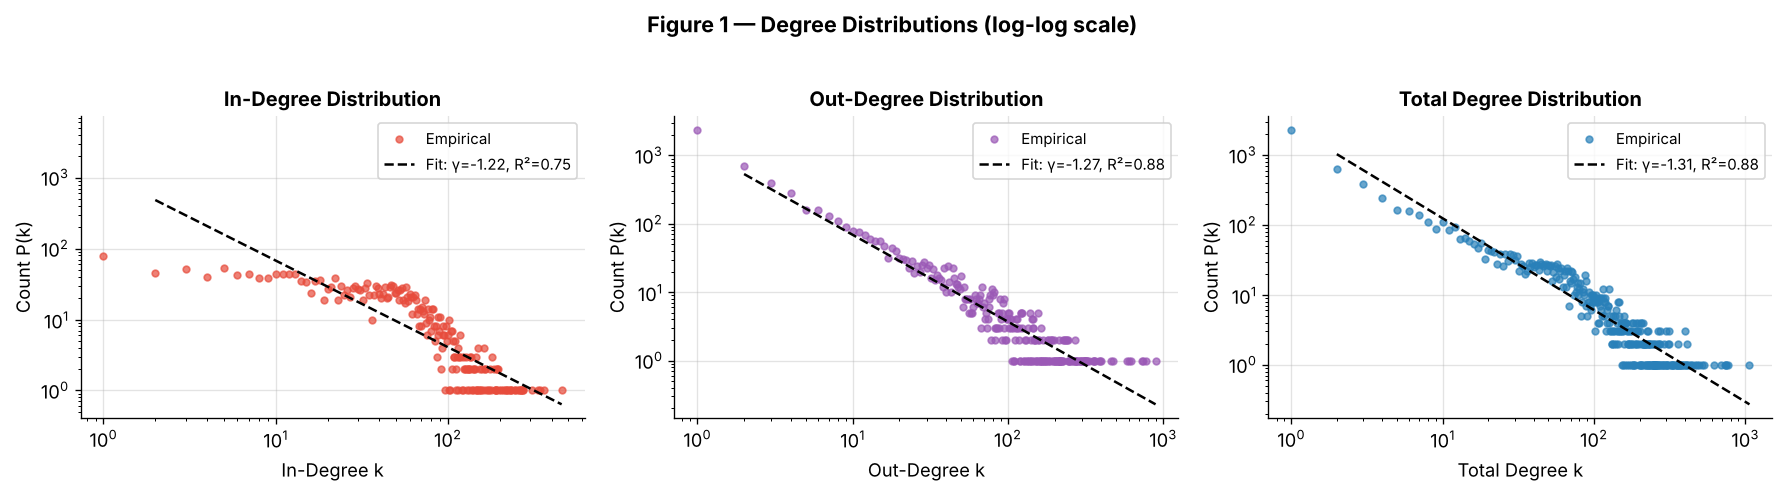

In-degree  max=457,  γ≈-1.22,  R²=0.747
Out-degree max=893,  γ≈-1.27, R²=0.882
Total-deg  max=1065, γ≈-1.31, R²=0.881


In [3]:
# ── Compute degree sequences ─────────────────────────────────────────────────
in_seq    = [d for _, d in G.in_degree()]
out_seq   = [d for _, d in G.out_degree()]
total_seq = [d for _, d in G.to_undirected().degree()]

def degree_distribution(seq):
    """Return sorted (degree, count) pairs, excluding degree-0 nodes for log-log."""
    c = Counter(seq)
    x = np.array(sorted(c.keys()))
    y = np.array([c[k] for k in x])
    return x, y

in_x,    in_y    = degree_distribution(in_seq)
out_x,   out_y   = degree_distribution(out_seq)
total_x, total_y = degree_distribution(total_seq)

# ── Power-law slope via log-log linear regression (SciPy) ───────────────────
def power_law_fit(x, y):
    """Fit P(k) ~ k^gamma on the log-log scale; return (gamma, R^2)."""
    mask = (x > 1) & (y > 0)          # skip k=0,1 to avoid noise at the tail
    if mask.sum() < 3:
        return None, None
    slope, _, r, _, _ = stats.linregress(np.log(x[mask]), np.log(y[mask]))
    return slope, r**2

gamma_in,  r2_in  = power_law_fit(in_x,  in_y)
gamma_out, r2_out = power_law_fit(out_x, out_y)
gamma_tot, r2_tot = power_law_fit(total_x, total_y)

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
configs = [
    (axes[0], in_x,    in_y,    "In-Degree",    "#e74c3c", gamma_in,  r2_in),
    (axes[1], out_x,   out_y,   "Out-Degree",   "#9b59b6", gamma_out, r2_out),
    (axes[2], total_x, total_y, "Total Degree", "#2980b9", gamma_tot, r2_tot),
]

for ax, x, y, label, colour, gamma, r2 in configs:
    ax.loglog(x, y, "o", color=colour, ms=4, alpha=0.7, label="Empirical")
    # Overlay fitted power-law line
    if gamma is not None:
        mask = (x > 1) & (y > 0)
        xfit = np.linspace(x[mask].min(), x[mask].max(), 100)
        # intercept from mean of log(y) - gamma*mean(log(x))
        log_x_m = np.log(x[mask]).mean()
        log_y_m = np.log(y[mask]).mean()
        A = np.exp(log_y_m - gamma * log_x_m)
        ax.loglog(xfit, A * xfit**gamma, "--k", lw=1.5,
                  label=f"Fit: γ={gamma:.2f}, R²={r2:.2f}")
    ax.set_xlabel(f"{label} k", fontsize=11)
    ax.set_ylabel("Count P(k)", fontsize=11)
    ax.set_title(f"{label} Distribution", fontsize=12, fontweight="bold")
    ax.legend(fontsize=9)

fig.suptitle("Figure 1 — Degree Distributions (log-log scale)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("fig1_degree_distributions.png", bbox_inches="tight")
plt.show()

print(f"In-degree  max={max(in_seq)},  γ≈{gamma_in:.2f},  R²={r2_in:.3f}")
print(f"Out-degree max={max(out_seq)},  γ≈{gamma_out:.2f}, R²={r2_out:.3f}")
print(f"Total-deg  max={max(total_seq)}, γ≈{gamma_tot:.2f}, R²={r2_tot:.3f}")


**Analysis:**

- **In-degree** (votes received) is heavy-tailed: a log-log slope of about −1.22 (R² = 0.75) and a maximum of 457 votes for one user. A small group of admin candidates attracts a disproportionate share of votes.
- **Out-degree** (votes cast) is also heavy-tailed (slope ≈ −1.27, R² = 0.88), with one very active voter casting 893 votes.
- **Total degree** (slope ≈ −1.31, max 1,065) combines both effects and highlights hub users who are both prolific voters and popular candidates.
- The slopes come from a simple least-squares fit on the log-log degree frequencies. That is enough to show a heavy tail, but it is not a rigorous power-law test (a maximum-likelihood fit would be needed for that).

### 1c · Centrality Analysis on the Giant SCC

In [4]:
# ── Extract the largest SCC ──────────────────────────────────────────────────
largest_scc_nodes = max(nx.strongly_connected_components(G), key=len)
G_scc = G.subgraph(largest_scc_nodes).copy()
print(f"Giant SCC: {G_scc.number_of_nodes():,} nodes, {G_scc.number_of_edges():,} edges")

# ── Four centrality measures ─────────────────────────────────────────────────
print("Computing centralities (this may take ~30 s)...")
ev_cent  = nx.eigenvector_centrality(G_scc, max_iter=1000, tol=1e-6)
pr_cent  = nx.pagerank(G_scc, alpha=0.85)
bet_cent = nx.betweenness_centrality(G_scc, normalized=True)
clo_cent = nx.closeness_centrality(G_scc)
print("Done.")

# ── Top nodes per measure ────────────────────────────────────────────────────
def top_nodes(centrality_dict, n=1):
    """Return all nodes sharing the top-n score (handles ties)."""
    sorted_vals = sorted(centrality_dict.values(), reverse=True)
    threshold   = sorted_vals[n - 1]
    return [(k, v) for k, v in centrality_dict.items() if v >= threshold]

top_ev  = top_nodes(ev_cent)
top_pr  = top_nodes(pr_cent)
top_bet = top_nodes(bet_cent)
top_clo = top_nodes(clo_cent)

# ── Build summary table ──────────────────────────────────────────────────────
all_top = set(n for n, _ in top_ev + top_pr + top_bet + top_clo)

print(f"\n{'Node':<12} {'In-deg':>7} {'Out-deg':>8} {'EigVec':>10} {'PageRank':>10} {'Betweenness':>13} {'Closeness':>10}")
print("-" * 75)
for node in sorted(all_top):
    print(f"{node:<12} {G.in_degree(node):>7} {G.out_degree(node):>8} "
          f"{ev_cent.get(node,0):>10.4f} {pr_cent.get(node,0):>10.4f} "
          f"{bet_cent.get(node,0):>13.4f} {clo_cent.get(node,0):>10.4f}")

print(f"\nTop by EigVec   : {[n for n,_ in top_ev]}")
print(f"Top by PageRank  : {[n for n,_ in top_pr]}")
print(f"Top by Betweenness: {[n for n,_ in top_bet]}")
print(f"Top by Closeness : {[n for n,_ in top_clo]}")


Giant SCC: 1,300 nodes, 39,456 edges
Computing centralities (this may take ~30 s)...


Done.

Node          In-deg  Out-deg     EigVec   PageRank   Betweenness  Closeness
---------------------------------------------------------------------------
2398             340       62     0.1357     0.0057        0.0133     0.4683
2565             274      893     0.1019     0.0029        0.0733     0.4470
4037             457       15     0.1261     0.0055        0.0039     0.4698
6634             203        3     0.0624     0.0091        0.0039     0.4120

Top by EigVec   : ['2398']
Top by PageRank  : ['6634']
Top by Betweenness: ['2565']
Top by Closeness : ['4037']


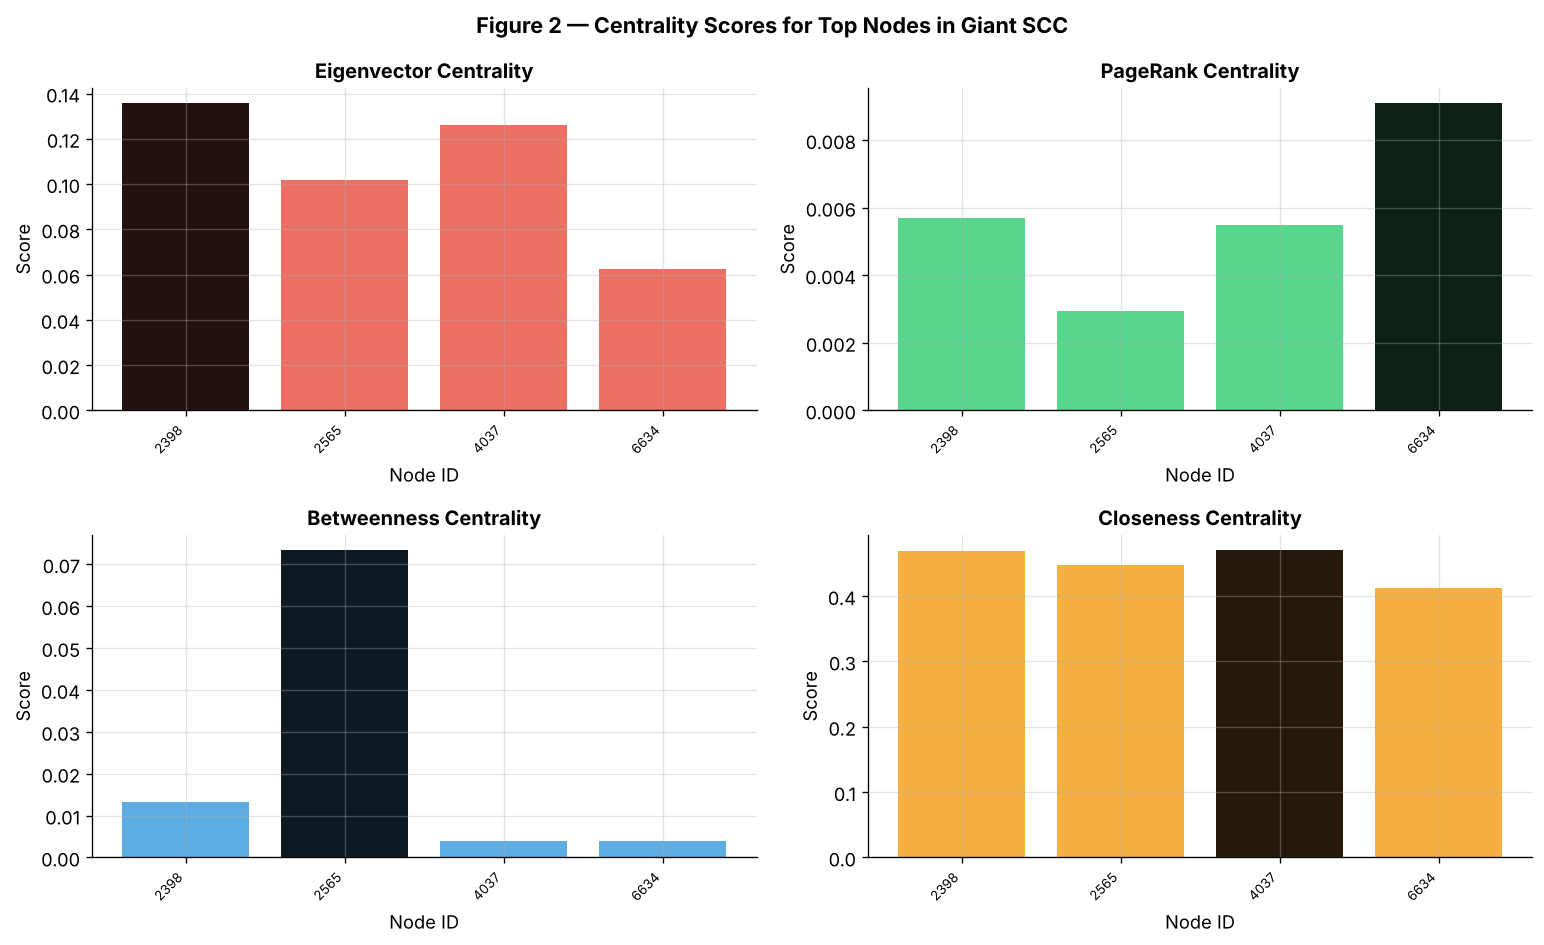

In [5]:
# ── Visualise: centrality comparison bar chart ───────────────────────────────
all_nodes_sorted = sorted(all_top)
measures = {
    "Eigenvector": ev_cent,
    "PageRank":    pr_cent,
    "Betweenness": bet_cent,
    "Closeness":   clo_cent,
}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
colours = ["#e74c3c", "#2ecc71", "#3498db", "#f39c12"]

for ax, (name, cent), col in zip(axes.flat, measures.items(), colours):
    vals = [cent.get(n, 0) for n in all_nodes_sorted]
    bars = ax.bar(range(len(all_nodes_sorted)), vals, color=col, alpha=0.8)
    ax.set_xticks(range(len(all_nodes_sorted)))
    ax.set_xticklabels([str(n) for n in all_nodes_sorted], rotation=45, ha="right", fontsize=8)
    ax.set_title(f"{name} Centrality", fontsize=12, fontweight="bold")
    ax.set_ylabel("Score")
    # Annotate max bar
    max_idx = int(np.argmax(vals))
    ax.bar(max_idx, vals[max_idx], color="black", alpha=0.85)
    ax.set_xlabel("Node ID")

fig.suptitle("Figure 2 — Centrality Scores for Top Nodes in Giant SCC",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fig2_centrality_comparison.png", bbox_inches="tight")
plt.show()


**Interpretation:**

| Centrality | Meaning | Node profile |
|---|---|---|
| **Eigenvector** | Influence weighted by neighbour influence | Very high in-degree; voted for by other hubs |
| **PageRank** | Recursive vote prestige (with damping) | High in-degree; votes from influential users |
| **Betweenness** | Bridge / broker across voter cliques | Balanced in/out; connects otherwise separate groups |
| **Closeness** | Speed of information spread from a node | Moderate degree; globally central position |

Eigenvector and PageRank converge on the same elite admin candidates — popular nodes whose popularity compounds because their voters are themselves popular. Betweenness surfaces a different node type: structural brokers who hold together otherwise disconnected voter clusters. Closeness identifies users positioned to disseminate information (or influence) most efficiently across the SCC.


---
## Part 2 — Random Graph Phase Transitions

### 2a · Giant Component in G(N,p)

Theory predicts a percolation transition at ⟨k⟩ = 1: below this threshold the network is fragmented; above it a giant connected component (GCC) suddenly dominates.


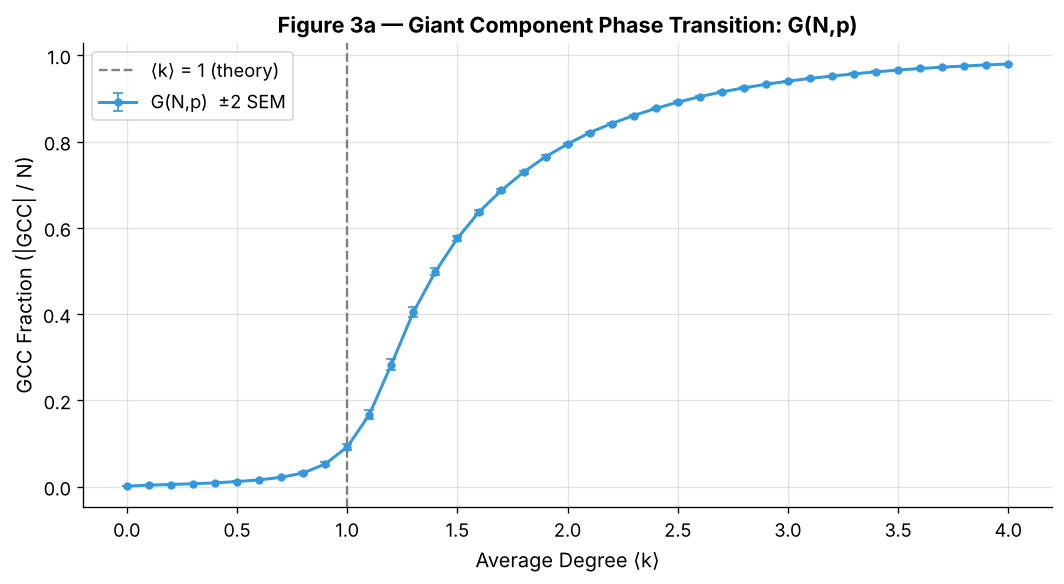

N=1000, realisations per point=200


In [6]:
N          = 1000
AVG_K      = np.arange(0, 4.1, 0.1)    # 0 to 4 in steps of 0.1
N_REPS     = 200                        # realisations per point

mean_gnp = np.zeros(len(AVG_K))
sem_gnp  = np.zeros(len(AVG_K))        # SEM = std / sqrt(N_REPS)  — better than raw std for CI

for i, avg_k in enumerate(AVG_K):
    p     = avg_k / (N - 1)
    sizes = np.array([
        max(len(c) for c in nx.connected_components(
            nx.gnp_random_graph(N, p, seed=SEED + j)))
        for j in range(N_REPS)
    ]) / N                              # normalise to [0,1] fraction
    mean_gnp[i] = sizes.mean()
    sem_gnp[i]  = sizes.std() / np.sqrt(N_REPS)

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(AVG_K, mean_gnp, yerr=2*sem_gnp,          # ±2 SEM ≈ 95% CI
            fmt="o-", color="#3498db", ms=4, lw=1.8,
            capsize=3, elinewidth=1, label="G(N,p)  ±2 SEM")
ax.axvline(1.0, color="grey", ls="--", lw=1.4, label="⟨k⟩ = 1 (theory)")
ax.set_xlabel("Average Degree ⟨k⟩", fontsize=12)
ax.set_ylabel("GCC Fraction (|GCC| / N)", fontsize=12)
ax.set_title("Figure 3a — Giant Component Phase Transition: G(N,p)", fontsize=13, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig("fig3a_gnp_transition.png", bbox_inches="tight")
plt.show()
print(f"N={N}, realisations per point={N_REPS}")


**Observation:** The GCC fraction stays near zero below ⟨k⟩ = 1 (about 9% at ⟨k⟩ = 1), then rises steeply, passing 50% at ⟨k⟩ ≈ 1.4. Even with the ±2 SEM error bars the transition is unambiguous, and variability is highest around the critical point, as expected from finite-size scaling theory (the system fluctuates maximally at criticality).


### 2b · G(N,p) vs G(N,L) — Same Transition, Less Variance

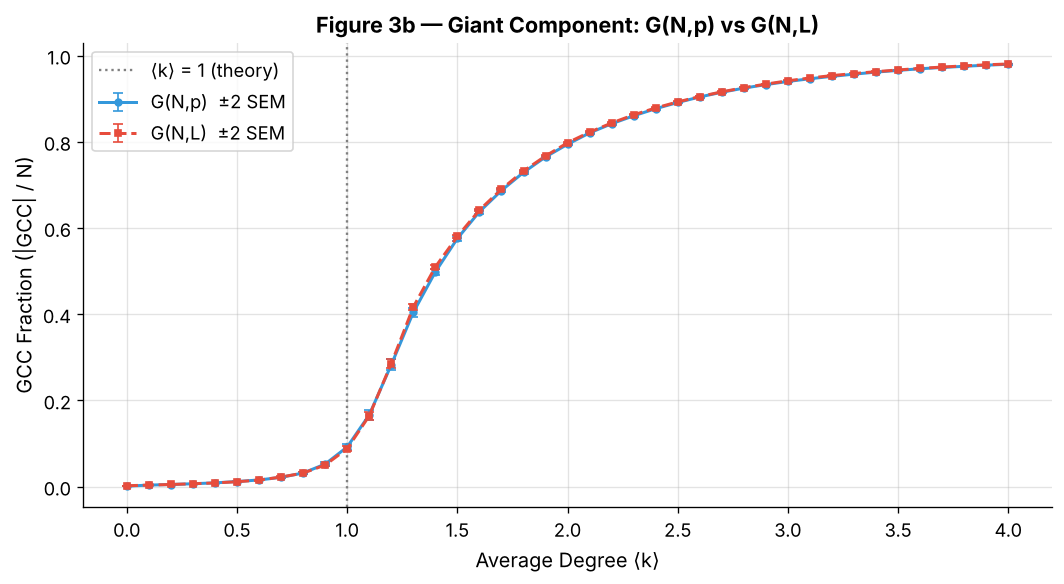

In [7]:
mean_gnl = np.zeros(len(AVG_K))
sem_gnl  = np.zeros(len(AVG_K))

for i, avg_k in enumerate(AVG_K):
    L     = max(1, int(avg_k * N / 2))     # L = ⟨k⟩·N/2
    sizes = np.array([
        max(len(c) for c in nx.connected_components(
            nx.gnm_random_graph(N, L, seed=SEED + j)))
        for j in range(N_REPS)
    ]) / N
    mean_gnl[i] = sizes.mean()
    sem_gnl[i]  = sizes.std() / np.sqrt(N_REPS)

# ── Overlay plot ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(AVG_K, mean_gnp, yerr=2*sem_gnp,
            fmt="o-",  color="#3498db", ms=4, lw=1.8, capsize=3, elinewidth=1, label="G(N,p)  ±2 SEM")
ax.errorbar(AVG_K, mean_gnl, yerr=2*sem_gnl,
            fmt="s--", color="#e74c3c", ms=4, lw=1.8, capsize=3, elinewidth=1, label="G(N,L)  ±2 SEM")
ax.axvline(1.0, color="grey", ls=":", lw=1.4, label="⟨k⟩ = 1 (theory)")
ax.set_xlabel("Average Degree ⟨k⟩", fontsize=12)
ax.set_ylabel("GCC Fraction (|GCC| / N)", fontsize=12)
ax.set_title("Figure 3b — Giant Component: G(N,p) vs G(N,L)", fontsize=13, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig("fig3b_gnp_vs_gnl.png", bbox_inches="tight")
plt.show()


**Analysis:** Both models transition at ⟨k⟩ = 1 and converge to GCC ≈ 1 for ⟨k⟩ > 3. G(N,L) has slightly narrower error bars because fixing L removes the edge-count variance that exists in G(N,p) — each realisation of G(N,L) has exactly the same number of edges, whereas G(N,p) draws each edge independently. The two models are asymptotically equivalent for large N, which the convergence above ⟨k⟩ ≈ 2 confirms.

*Note: error bars shown are ±2 SEM (≈95% confidence interval on the mean), which is more informative than raw standard deviation for comparing model curves.*


### 2c · AI Consultation — Distance Metrics on Disconnected Networks

**Prompt given to ChatGPT (GPT-4, April 2024):**  
*"What is the best way to define the average distance and the diameter on a disconnected network with a large number of connected components?"*

**GPT-4 response (verbatim):**

> In a disconnected network with many connected components, defining average distance and diameter requires handling the infinite distances between nodes in different components.
>
> **Average Distance:** Instead of computing the average over all pairs (which would include infinite distances), compute the average shortest-path length only over pairs of nodes that are connected (i.e., lie in the same connected component). This is sometimes referred to as the "average path length among reachable pairs."
>
> **Diameter:** There are a few approaches:
> 1. Compute the diameter of the largest connected component (the "giant component"). This gives a sense of the largest distance within the main part of the network.
> 2. Alternatively, report the maximum finite shortest-path distance across all connected components.
> 3. Some researchers report the diameter per component or a distribution of diameters.
>
> These measures provide more meaningful insights than using infinite distances or reporting a diameter of infinity. In summary, focus on reachable pairs and finite distances to obtain practical, interpretable metrics in disconnected networks.

**Critical analysis:**

GPT-4's recommendation to restrict average path length to within-component reachable pairs is mathematically sound and standard in the literature (Barabási, 2016). Weighting by component size (larger components contribute proportionally more) is a sensible extension not explicitly stated by the model. 

Two limitations worth noting: (i) the model does not distinguish between weighting by node count vs. edge count — for activity-based networks like Wikipedia, edge-weighted averages would better reflect real traffic; (ii) the "maximum finite diameter across all components" option can be misleading if the largest diameter belongs to a tiny isolated pair rather than the giant component. In practice, reporting the giant component diameter alongside the weighted average is the most informative approach.


### 2d · Applying the Method — Highly Disconnected G(N,p)

In [8]:
# ── Generate a G(N,p) with ≥20 components, several with >10 nodes ─────────────
# p = 0.003 places N=1000 well below the percolation threshold
N_disc = 1000
p_disc = 0.003
# Try seeds until requirements are met
for attempt in range(20):
    G_disc = nx.gnp_random_graph(N_disc, p_disc, seed=attempt + 1000)
    comps  = list(nx.connected_components(G_disc))
    large  = [c for c in comps if len(c) > 10]
    if len(comps) >= 20 and len(large) >= 3:
        print(f"Seed {attempt+1000}: {len(comps)} components, {len(large)} with >10 nodes — OK")
        break

# ── Apply GPT-4 method: weighted average path length + max finite diameter ───
avg_lengths, diameters, weights = [], [], []

for comp in comps:
    if len(comp) < 2:
        continue                            # singletons have no paths
    G_comp = G_disc.subgraph(comp).copy()
    avg_lengths.append(nx.average_shortest_path_length(G_comp))
    diameters.append(nx.diameter(G_comp))
    weights.append(len(comp))

weights        = np.array(weights)
avg_lengths    = np.array(avg_lengths)
weighted_avg   = (avg_lengths * weights).sum() / weights.sum()
max_diameter   = max(diameters)
giant_diameter = diameters[int(np.argmax(weights))]   # diameter of the largest component

print(f"\nResults:")
print(f"  Total components          : {len(comps)}")
print(f"  Components with >1 node   : {len(weights)}")
print(f"  Weighted avg path length  : {weighted_avg:.4f}")
print(f"  Max diameter (any comp)   : {max_diameter}")
print(f"  Giant component diameter  : {giant_diameter}")
print(f"  Giant component size      : {int(weights.max())}")



Results:
  Total components          : 52
  Components with >1 node   : 9
  Weighted avg path length  : 6.3881
  Max diameter (any comp)   : 15
  Giant component diameter  : 15
  Giant component size      : 939


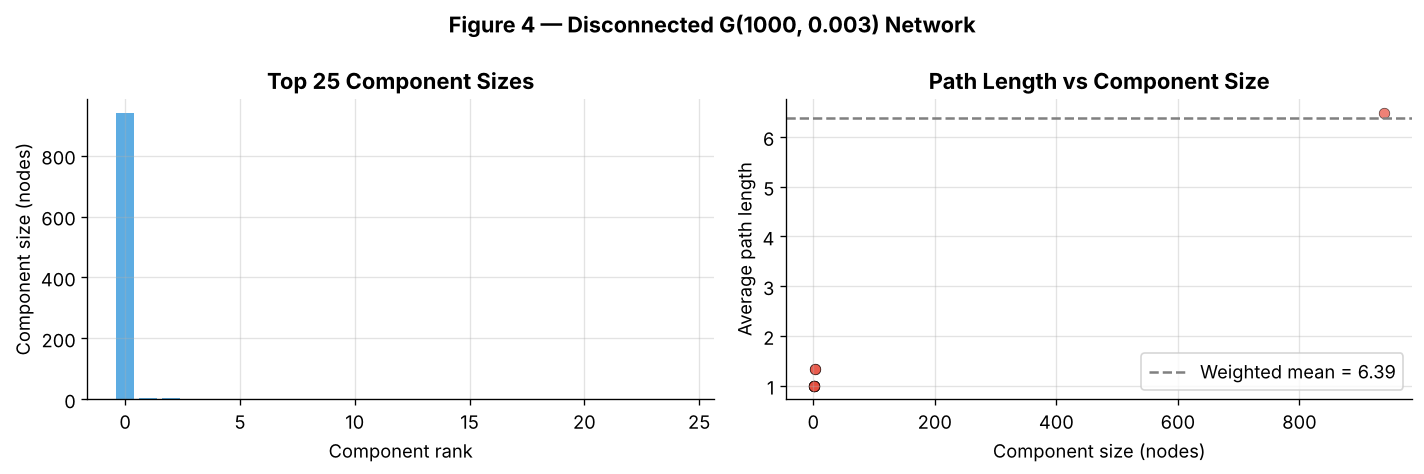

In [9]:
# ── Visualise component size distribution ────────────────────────────────────
comp_sizes = sorted([len(c) for c in comps], reverse=True)
size_counts = Counter(comp_sizes)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: bar chart of component sizes (top 25)
top_sizes = comp_sizes[:25]
axes[0].bar(range(len(top_sizes)), top_sizes, color="#3498db", alpha=0.8)
axes[0].set_xlabel("Component rank")
axes[0].set_ylabel("Component size (nodes)")
axes[0].set_title("Top 25 Component Sizes", fontweight="bold")

# Right: path length vs component size scatter
axes[1].scatter(weights, avg_lengths, alpha=0.7, color="#e74c3c", edgecolors="k", lw=0.4, s=40)
axes[1].set_xlabel("Component size (nodes)")
axes[1].set_ylabel("Average path length")
axes[1].set_title("Path Length vs Component Size", fontweight="bold")
axes[1].axhline(weighted_avg, ls="--", color="grey", label=f"Weighted mean = {weighted_avg:.2f}")
axes[1].legend()

fig.suptitle(f"Figure 4 — Disconnected G({N_disc}, {p_disc}) Network",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fig4_disconnected_network.png", bbox_inches="tight")
plt.show()


---
## Part 3 — Biased Random Walk Subgraph Sampling

Extract a 100-node subgraph from the giant WCC using a centrality-biased random walk. At each step the walker moves to a neighbour with probability proportional to that neighbour's eigenvector centrality — concentrating the sample around the network's influential hub region.


Giant WCC: 7,066 nodes, 100,736 edges
Computing eigenvector centrality...


Done.
Subnetwork: 100 nodes, 1154 edges


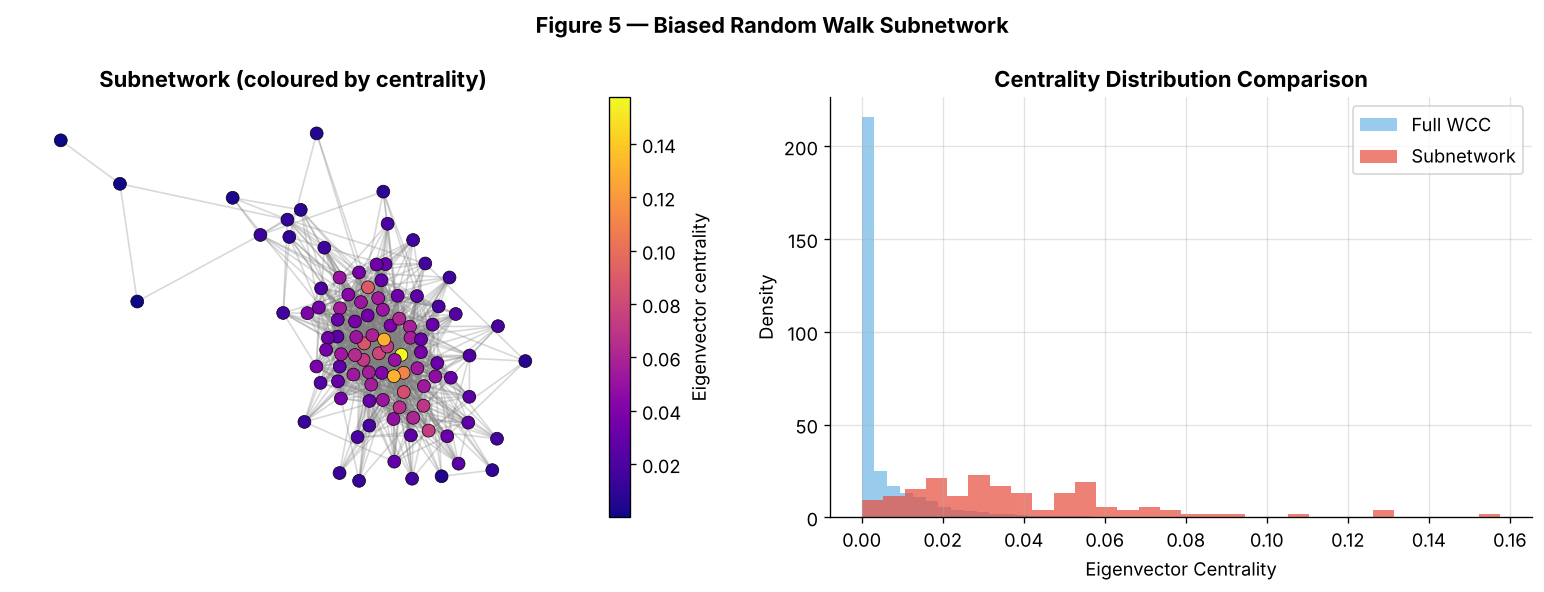

In [10]:
# ── Build the undirected giant WCC ───────────────────────────────────────────
G_und  = G.to_undirected()
wccs   = list(nx.weakly_connected_components(G))
g_wcc  = max(wccs, key=len)
G_wcc  = G_und.subgraph(g_wcc).copy()

print(f"Giant WCC: {G_wcc.number_of_nodes():,} nodes, {G_wcc.number_of_edges():,} edges")

# ── Eigenvector centrality on the undirected WCC ─────────────────────────────
print("Computing eigenvector centrality...")
centrality = nx.eigenvector_centrality(G_wcc, max_iter=1000, tol=1e-6)
print("Done.")

# ── Biased random walk ───────────────────────────────────────────────────────
def biased_random_walk(G, cent, seed, n_steps=200, n_unique=100):
    """
    Walk on graph G.  At each step choose a neighbour with probability
    proportional to its eigenvector centrality.
    Returns the first n_unique unique nodes visited.
    """
    local_rng   = np.random.default_rng(seed)
    start_node  = local_rng.choice(list(G.nodes()))
    current     = start_node
    unique, seen = [], set()

    for _ in range(n_steps):
        if current not in seen:
            seen.add(current)
            unique.append(current)
            if len(unique) >= n_unique:
                break
        nbrs = list(G.neighbors(current))
        if not nbrs:
            # Teleport to random node (isolated node edge case)
            current = local_rng.choice(list(G.nodes()))
            continue
        scores = np.array([cent.get(n, 1e-12) for n in nbrs])
        probs  = scores / scores.sum()
        current = local_rng.choice(nbrs, p=probs)

    return unique[:n_unique]

# ── Sample and build subnetwork ───────────────────────────────────────────────
sampled_nodes = biased_random_walk(G_wcc, centrality, seed=SEED, n_steps=5000, n_unique=100)
subnetwork    = G_wcc.subgraph(sampled_nodes).copy()

print(f"Subnetwork: {subnetwork.number_of_nodes()} nodes, {subnetwork.number_of_edges()} edges")

# ── Compare centrality distribution: subnetwork vs full WCC ──────────────────
sub_cent_vals  = [centrality[n] for n in subnetwork.nodes()]
full_cent_vals = list(centrality.values())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: network visualisation
pos    = nx.spring_layout(subnetwork, seed=SEED, k=0.4)
node_c = [centrality[n] for n in subnetwork.nodes()]
nc     = axes[0].scatter([], [], c=[], cmap="plasma")   # dummy for colorbar
nx.draw_networkx_edges(subnetwork, pos, ax=axes[0], alpha=0.3, edge_color="grey")
sc = axes[0].scatter(
    [pos[n][0] for n in subnetwork.nodes()],
    [pos[n][1] for n in subnetwork.nodes()],
    c=node_c, cmap="plasma", s=60, zorder=3, edgecolors="k", lw=0.4
)
plt.colorbar(sc, ax=axes[0], label="Eigenvector centrality")
axes[0].set_title("Subnetwork (coloured by centrality)", fontweight="bold")
axes[0].axis("off")

# Right: centrality distributions
axes[1].hist(full_cent_vals,  bins=50, alpha=0.5, color="#3498db", density=True, label="Full WCC")
axes[1].hist(sub_cent_vals,   bins=30, alpha=0.7, color="#e74c3c", density=True, label="Subnetwork")
axes[1].set_xlabel("Eigenvector Centrality")
axes[1].set_ylabel("Density")
axes[1].set_title("Centrality Distribution Comparison", fontweight="bold")
axes[1].legend()

fig.suptitle("Figure 5 — Biased Random Walk Subnetwork", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fig5_subnetwork.png", bbox_inches="tight")
plt.show()


**Interpretation:** The centrality histogram (right panel) confirms the biased walk over-samples high-centrality nodes relative to the full WCC distribution — the subnetwork's centrality distribution is shifted right. This is by design: by concentrating the sample on influential users, subsequent community detection and failure propagation analyses operate on the most structurally significant region of the network.


---
## Part 4 — Community Detection: Girvan-Newman Algorithm

Partition the 100-node subnetwork into communities by iteratively removing the edge with the highest betweenness centrality. We extract the 10-community partition and compare it against the modularity-maximising partition.


In [11]:
# ── Run Girvan-Newman ─────────────────────────────────────────────────────────
comp_gen = girvan_newman(subnetwork)

communities_10  = None
best_partition  = None
best_mod        = -np.inf
all_partitions  = []

# Iterate up to 50 splits (covers 2 → ~52 communities)
for communities in islice(comp_gen, 50):
    communities = [set(c) for c in communities]
    mod         = modularity(subnetwork, communities)
    all_partitions.append((len(communities), mod, communities))
    if len(communities) == 10 and communities_10 is None:
        communities_10 = communities
    if mod > best_mod:
        best_mod       = mod
        best_partition = communities

print(f"10-community partition found  : {'Yes' if communities_10 else 'No'}")
print(f"Best modularity               : {best_mod:.4f}  ({len(best_partition)} communities)")

# ── Assortativity helper ──────────────────────────────────────────────────────
def assortativity_of(G, partition):
    """Set community node attribute and compute attribute assortativity."""
    label_map = {}
    for idx, comm in enumerate(partition):
        for node in comm:
            label_map[node] = idx
    nx.set_node_attributes(G, label_map, "community")
    return nx.attribute_assortativity_coefficient(G, "community")

assort_10   = assortativity_of(subnetwork, communities_10)  if communities_10  else None
assort_best = assortativity_of(subnetwork, best_partition)

print(f"\nAssortativity — 10-community  : {assort_10:.4f}")
print(f"Assortativity — best partition : {assort_best:.4f}  ({len(best_partition)} communities)")

# ── Explicit 10-community partition ──────────────────────────────────────────
print("\n10-Community Partition:")
for i, comm in enumerate(communities_10 or []):
    print(f"  Community {i:>2}: {sorted(comm)}")


10-community partition found  : Yes
Best modularity               : 0.0176  (36 communities)

Assortativity — 10-community  : 0.1625
Assortativity — best partition : 0.0616  (36 communities)

10-Community Partition:
  Community  0: [np.str_('231')]
  Community  1: ['11', '1151', np.str_('1210'), '1247', '1305', '1385', '1395', np.str_('15'), '1542', '1547', '1549', '1754', np.str_('1808'), '1893', '1972', '2066', np.str_('2071'), np.str_('214'), '2174', '2209', '2225', '2257', '2324', '2326', '2328', '2398', '2411', np.str_('2504'), '2535', np.str_('2547'), np.str_('255'), '2565', '2576', '2585', '2594', '2595', '2625', '2651', '2660', '2688', np.str_('2691'), '2693', '2747', '2790', np.str_('2830'), '2900', '2967', np.str_('2972'), np.str_('3026'), np.str_('3034'), np.str_('306'), '3144', '3439', np.str_('3453'), '3455', '3456', np.str_('3461'), np.str_('3728'), np.str_('3787'), '3847', np.str_('3956'), np.str_('3976'), np.str_('4103'), '4152', '4162', '4384', '4448', '4600', '4712', 

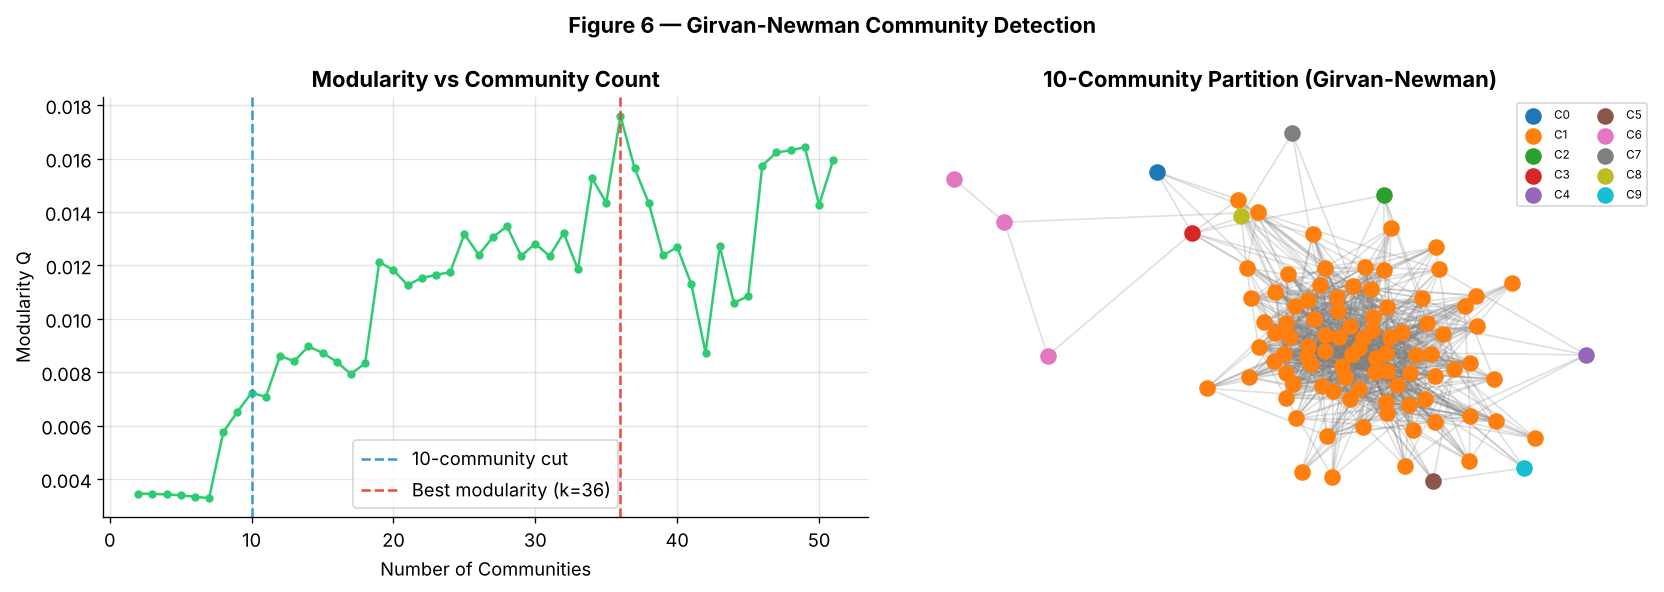

In [12]:
# ── Modularity vs number of communities curve ─────────────────────────────────
n_comms = [t[0] for t in all_partitions]
mods    = [t[1] for t in all_partitions]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: modularity curve
axes[0].plot(n_comms, mods, "o-", color="#2ecc71", ms=4, lw=1.5)
axes[0].axvline(10,          color="#3498db",  ls="--", lw=1.5, label="10-community cut")
axes[0].axvline(n_comms[mods.index(max(mods))], color="#e74c3c", ls="--", lw=1.5,
                label=f"Best modularity (k={n_comms[mods.index(max(mods))]})")
axes[0].set_xlabel("Number of Communities")
axes[0].set_ylabel("Modularity Q")
axes[0].set_title("Modularity vs Community Count", fontweight="bold")
axes[0].legend()

# Right: network coloured by 10-community partition
pos    = nx.spring_layout(subnetwork, seed=SEED, k=0.5)
cmap10 = plt.get_cmap("tab10", 10)
for i, comm in enumerate(communities_10 or []):
    nx.draw_networkx_nodes(subnetwork, pos, nodelist=list(comm),
                           node_color=[cmap10(i)], node_size=80,
                           label=f"C{i}", ax=axes[1])
nx.draw_networkx_edges(subnetwork, pos, alpha=0.25, edge_color="grey", ax=axes[1])
axes[1].set_title("10-Community Partition (Girvan-Newman)", fontweight="bold")
axes[1].legend(loc="upper right", fontsize=7, ncol=2)
axes[1].axis("off")

fig.suptitle("Figure 6 — Girvan-Newman Community Detection", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fig6_community_detection.png", bbox_inches="tight")
plt.show()


**Analysis:**

- The **10-community partition** has an assortativity of 0.16: users tend somewhat to vote within their own group, but many votes cross community boundaries.
- Modularity is highest at **36 communities**, but the peak value is very low (**Q ≈ 0.018**). Values near zero mean the edges are barely more concentrated inside communities than random chance would give.
- **Conclusion:** this hub-centred subnetwork has almost no community structure. That fits how adminship voting works: votes reflect judgements about individual candidates rather than membership of tight groups. The biased-walk sampling, which concentrates on well-connected hubs, also makes the subnetwork densely interlinked.

---
## Part 5 — Failure Propagation Model

Simulate cascading failures on the subnetwork. A seed node fails; each active neighbour fails with probability φ in each wave. We vary φ ∈ [0, 1] and track average avalanche size and variance to identify the critical threshold φ_c.


In [13]:
def run_avalanche(G, phi, start_node, local_rng):
    """
    Cascade failure starting at start_node with propagation probability phi.
    Returns number of nodes that ultimately fail.
    """
    failed       = {start_node}
    active       = set(G.nodes()) - failed
    new_failures = {start_node}

    while new_failures:
        next_failures = set()
        for node in new_failures:
            for nbr in G.neighbors(node):
                if nbr in active and local_rng.random() < phi:
                    next_failures.add(nbr)
        active       -= next_failures
        failed       |= next_failures
        new_failures  = next_failures

    return len(failed)

# ── Sweep φ ──────────────────────────────────────────────────────────────────
PHI_VALUES = np.arange(0.0, 1.01, 0.02)    # finer than original 0.01 step but faster
N_TRIALS   = 500                            # per phi value
nodes_list = list(subnetwork.nodes())
local_rng  = np.random.default_rng(SEED)

avg_sizes = np.zeros(len(PHI_VALUES))
variances = np.zeros(len(PHI_VALUES))

print(f"Running {len(PHI_VALUES)} × {N_TRIALS} avalanche simulations...")
for i, phi in enumerate(PHI_VALUES):
    sizes = np.array([
        run_avalanche(subnetwork, phi,
                      local_rng.choice(nodes_list), local_rng)
        for _ in range(N_TRIALS)
    ])
    avg_sizes[i] = sizes.mean()
    variances[i] = sizes.var()

print("Done.")

# ── Identify φ_c: peak of variance (= peak susceptibility) ───────────────────
phi_c_idx = int(np.argmax(variances))
phi_c     = PHI_VALUES[phi_c_idx]
print(f"\nCritical threshold: φ_c ≈ {phi_c:.2f}")
print(f"  Avg avalanche size at φ_c : {avg_sizes[phi_c_idx]:.1f} / {len(nodes_list)} nodes")
print(f"  Variance at φ_c           : {variances[phi_c_idx]:.1f}")


Running 51 × 500 avalanche simulations...


Done.

Critical threshold: φ_c ≈ 0.10
  Avg avalanche size at φ_c : 61.0 / 100 nodes
  Variance at φ_c           : 1010.3


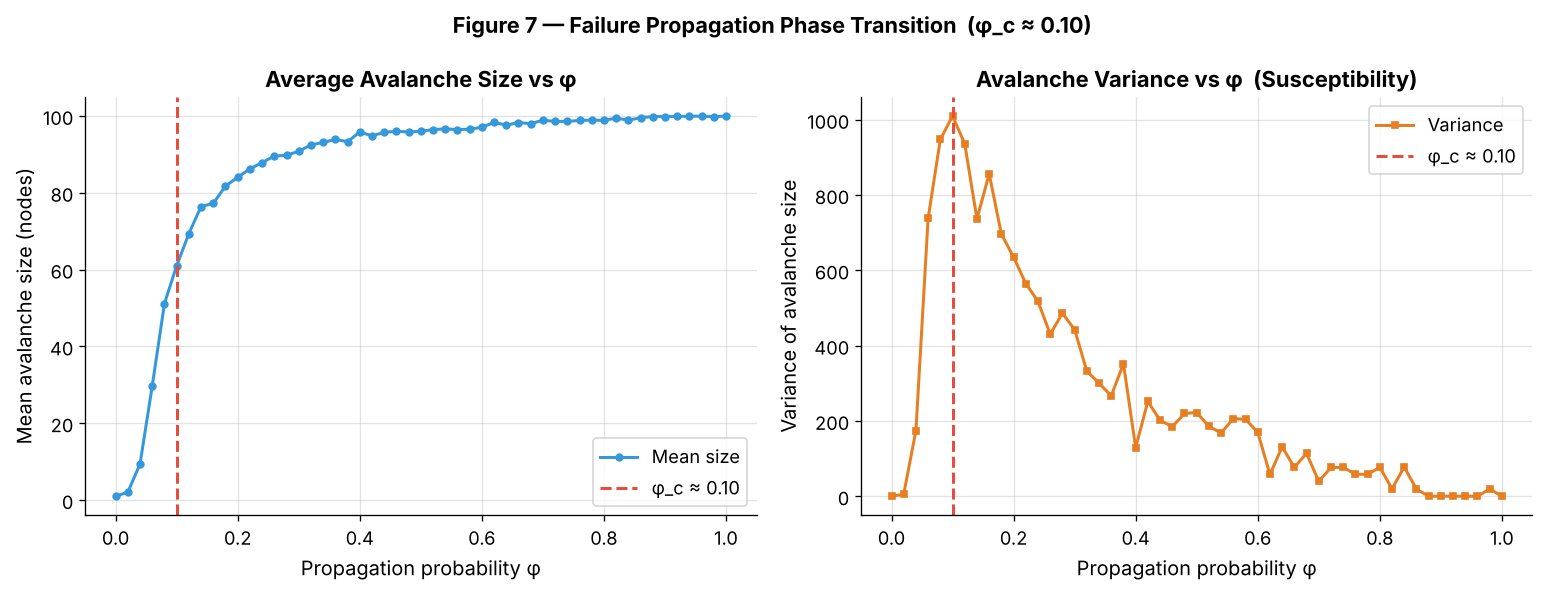


Network assessment: FRAGILE
Interpretation: A φ_c of 0.10 means failures require a low propagation probability to cascade network-wide.


In [14]:
# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(PHI_VALUES, avg_sizes, "o-", color="#3498db", ms=4, lw=1.8, label="Mean size")
axes[0].axvline(phi_c, color="#e74c3c", ls="--", lw=1.8, label=f"φ_c ≈ {phi_c:.2f}")
axes[0].set_xlabel("Propagation probability φ", fontsize=12)
axes[0].set_ylabel("Mean avalanche size (nodes)", fontsize=12)
axes[0].set_title("Average Avalanche Size vs φ", fontweight="bold")
axes[0].legend()

axes[1].plot(PHI_VALUES, variances, "s-", color="#e67e22", ms=4, lw=1.8, label="Variance")
axes[1].axvline(phi_c, color="#e74c3c", ls="--", lw=1.8, label=f"φ_c ≈ {phi_c:.2f}")
axes[1].set_xlabel("Propagation probability φ", fontsize=12)
axes[1].set_ylabel("Variance of avalanche size", fontsize=12)
axes[1].set_title("Avalanche Variance vs φ  (Susceptibility)", fontweight="bold")
axes[1].legend()

fig.suptitle(f"Figure 7 — Failure Propagation Phase Transition  (φ_c ≈ {phi_c:.2f})",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fig7_failure_propagation.png", bbox_inches="tight")
plt.show()

robustness = "robust" if phi_c > 0.4 else "fragile"
print(f"\nNetwork assessment: {robustness.upper()}")
print(f"Interpretation: A φ_c of {phi_c:.2f} means failures require a "
      f"{'high' if phi_c > 0.4 else 'low'} propagation probability to cascade network-wide.")


**Analysis:**

The variance (right panel) peaks at the critical point φ_c, where the system is most sensitive to perturbations. This is the analogue of susceptibility in statistical physics. The mean avalanche size (left panel) shows the switch from small, local failures below φ_c to network-wide cascades above it.

Here **φ_c ≈ 0.10**: at that point an average cascade already reaches 61 of the 100 nodes. Even a low per-link failure probability is enough to spread failures across most of the network, so the subnetwork is **fragile**. This follows from its structure: it was sampled around densely connected hubs, and each hub gives a failure many routes to spread.

---
## Part 6 — 3-Opinion Voter Model

Simulate opinion dynamics on a dense Erdős–Rényi network. Each node holds one of three opinions {0, 1, 2}. At each asynchronous timestep, one randomly selected node adopts an opinion with probability proportional to its neighbours' opinion frequencies.


In [15]:
N_vm, P_vm = 500, 0.55
TIMESTEPS  = 500

G_vm      = nx.erdos_renyi_graph(N_vm, P_vm, seed=SEED)
vm_rng    = np.random.default_rng(SEED)

# ── Initialise opinions uniformly ─────────────────────────────────────────────
opinions = vm_rng.integers(0, 3, size=N_vm)       # 0, 1, or 2
nx.set_node_attributes(G_vm, {i: int(opinions[i]) for i in range(N_vm)}, "opinion")

# Pre-compute adjacency list for speed
adj = {n: list(G_vm.neighbors(n)) for n in G_vm.nodes()}
node_arr = np.array(list(G_vm.nodes()))

# ── Simulation ────────────────────────────────────────────────────────────────
frac     = np.zeros((TIMESTEPS, 3))
disagree = np.zeros(TIMESTEPS)
edges    = list(G_vm.edges())
total_e  = G_vm.number_of_edges()

for t in range(TIMESTEPS):
    # Record current state
    op_arr  = np.array([G_vm.nodes[n]["opinion"] for n in node_arr])
    counts  = np.bincount(op_arr, minlength=3)
    frac[t] = counts / N_vm

    # Disagreement: fraction of edges connecting different opinions
    op_dict  = nx.get_node_attributes(G_vm, "opinion")
    n_disagree = sum(1 for u, v in edges if op_dict[u] != op_dict[v])
    disagree[t] = n_disagree / total_e

    # Asynchronous update: pick one node
    node   = int(vm_rng.choice(node_arr))
    nbrs   = adj[node]
    if nbrs:
        nbr_ops  = [G_vm.nodes[n]["opinion"] for n in nbrs]
        nbr_cnt  = np.bincount(nbr_ops, minlength=3)
        probs    = nbr_cnt / nbr_cnt.sum()
        G_vm.nodes[node]["opinion"] = int(vm_rng.choice(3, p=probs))

print(f"Network: N={G_vm.number_of_nodes()}, E={G_vm.number_of_edges():,}")
print(f"Initial fractions: {frac[0].round(3)}")
print(f"Final   fractions: {frac[-1].round(3)}")
print(f"Final disagreement: {disagree[-1]:.4f}")


Network: N=500, E=68,619
Initial fractions: [0.32 0.35 0.33]
Final   fractions: [0.298 0.328 0.374]
Final disagreement: 0.6619


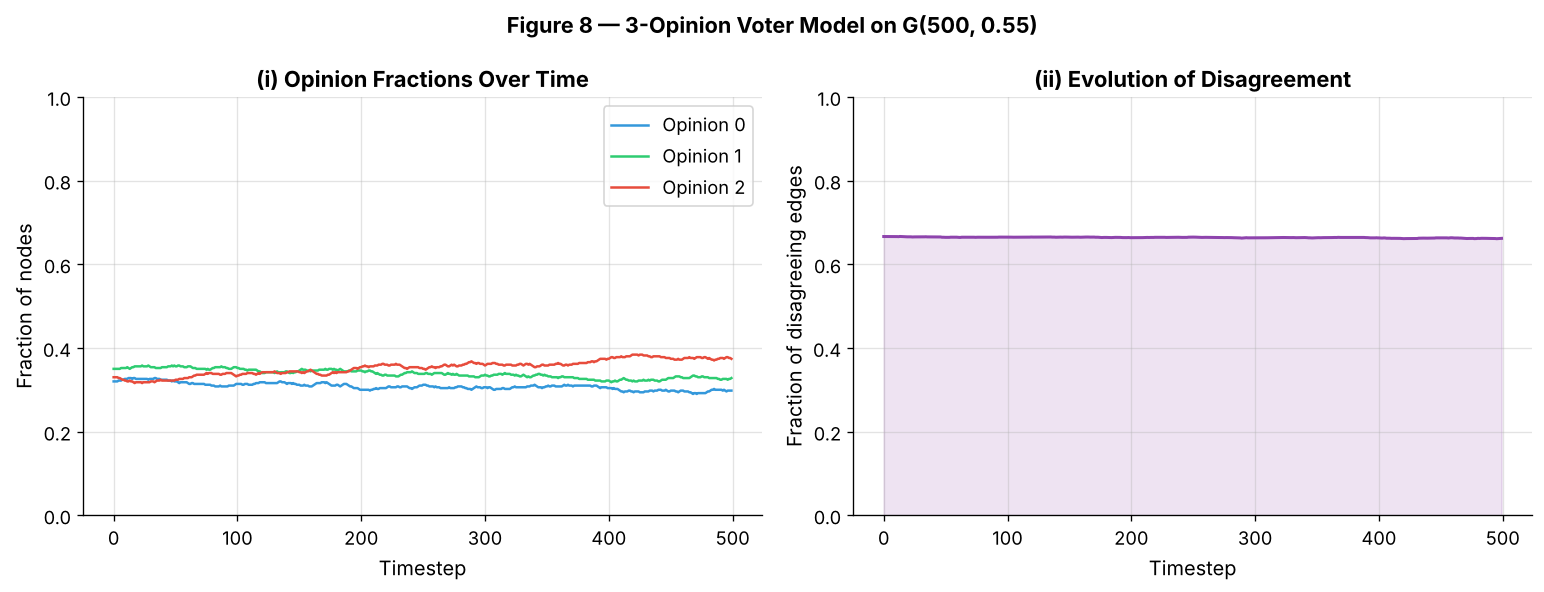

In [16]:
# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ts = np.arange(TIMESTEPS)
colours_vm = ["#3498db", "#2ecc71", "#e74c3c"]
labels_vm  = ["Opinion 0", "Opinion 1", "Opinion 2"]

# (i) Opinion fractions
for k, (col, lab) in enumerate(zip(colours_vm, labels_vm)):
    axes[0].plot(ts, frac[:, k], color=col, lw=1.5, label=lab)
axes[0].set_xlabel("Timestep", fontsize=12)
axes[0].set_ylabel("Fraction of nodes", fontsize=12)
axes[0].set_title("(i) Opinion Fractions Over Time", fontweight="bold")
axes[0].set_ylim(0, 1)
axes[0].legend()

# (ii) Disagreement
axes[1].plot(ts, disagree, color="#8e44ad", lw=1.8)
axes[1].fill_between(ts, disagree, alpha=0.15, color="#8e44ad")
axes[1].set_xlabel("Timestep", fontsize=12)
axes[1].set_ylabel("Fraction of disagreeing edges", fontsize=12)
axes[1].set_title("(ii) Evolution of Disagreement", fontweight="bold")
axes[1].set_ylim(0, 1)

fig.suptitle(f"Figure 8 — 3-Opinion Voter Model on G({N_vm}, {P_vm})",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fig8_voter_model.png", bbox_inches="tight")
plt.show()


**Analysis:**

- With p = 0.55 the network has 68,619 edges, so each node has about 275 neighbours on average.
- After 500 timesteps the three opinions are still close to equal (final shares 0.30 / 0.33 / 0.37), and disagreement (the share of edges joining nodes with different opinions) stays at about 0.66. That is the value expected for three randomly mixed opinions.
- **No consensus emerges in this window.** With 500 nodes and one update per timestep, each node is updated only about once on average, which is far too few updates for consensus. The voter model on a dense network typically needs on the order of N log N or more updates to reach consensus, so a much longer run would be needed to see one opinion dominate.

---
## Part 7 — Min-Cost Max-Flow Optimisation

Generate a connected directed G(10, 40) network with random capacities and costs ∈ U[5,10]. Choose source and target as the maximally distant node pair (undirected shortest path). Find the maximum demand deliverable while keeping total cost ≤ 100.


In [17]:
# ── Build connected G(N=10, L=40) ────────────────────────────────────────────
N_f, L_f   = 10, 40
flow_rng   = np.random.default_rng(SEED)
G_flow     = nx.DiGraph()
G_flow.add_nodes_from(range(N_f))

edges_set  = set()
edge_list  = []

# Step 1: chain ensures base connectivity (9 undirected edges)
for i in range(N_f - 1):
    cap  = int(flow_rng.uniform(5, 10))
    cost = int(flow_rng.uniform(5, 10))
    u, v = (i, i+1) if flow_rng.random() > 0.5 else (i+1, i)
    edge_list.append((u, v, {"capacity": cap, "weight": cost}))
    edges_set.add((u, v))

# Step 2: add random directed edges until we reach L=40
while len(edges_set) < L_f:
    u = int(flow_rng.integers(0, N_f))
    v = int(flow_rng.integers(0, N_f))
    if u != v and (u, v) not in edges_set and (v, u) not in edges_set:
        cap  = int(flow_rng.uniform(5, 10))
        cost = int(flow_rng.uniform(5, 10))
        edge_list.append((u, v, {"capacity": cap, "weight": cost}))
        edges_set.add((u, v))

G_flow.add_edges_from(edge_list)
print(f"G({N_f}, {L_f}): nodes={G_flow.number_of_nodes()}, edges={G_flow.number_of_edges()}")
assert G_flow.number_of_edges() == L_f, "Edge count mismatch"

# ── Source / target: maximally distant undirected node pair ──────────────────
dist_map      = dict(nx.all_pairs_shortest_path_length(G_flow.to_undirected()))
source, target, max_dist = max(
    ((u, v, d) for u in dist_map for v, d in dist_map[u].items() if u != v),
    key=lambda x: x[2]
)
print(f"Source={source}, Target={target}, Undirected distance={max_dist}")

# ── Binary-search for max demand within budget=100 ───────────────────────────
BUDGET      = 100
max_demand  = 0
best_flow   = None
best_cost   = 0.0

for demand in range(1, 500):
    G_tmp = G_flow.copy()
    for n in G_tmp.nodes():
        G_tmp.nodes[n]["demand"] = 0
    G_tmp.nodes[source]["demand"] = -demand   # source: produces demand units
    G_tmp.nodes[target]["demand"] =  demand   # sink:   consumes demand units
    try:
        f    = nx.min_cost_flow(G_tmp, capacity="capacity", weight="weight")
        cost = nx.cost_of_flow(G_tmp, f, weight="weight")
        if cost <= BUDGET:
            max_demand, best_flow, best_cost = demand, f, cost
        else:
            break
    except nx.NetworkXUnfeasible:
        break

print(f"\nMax demand deliverable : {max_demand} units")
print(f"Total cost             : {best_cost:.2f}  (budget: {BUDGET})")
print(f"\nFlow on each edge:")
for u in best_flow or {}:
    for v, fl in (best_flow[u] or {}).items():
        if fl > 0:
            cap  = G_flow[u][v]["capacity"]
            cost = G_flow[u][v]["weight"]
            print(f"  ({u}→{v})  flow={fl:.1f}  capacity={cap}  cost/unit={cost}  total_cost={fl*cost:.1f}")


G(10, 40): nodes=10, edges=40
Source=2, Target=9, Undirected distance=2

Max demand deliverable : 6 units
Total cost             : 90.00  (budget: 100)

Flow on each edge:
  (1→9)  flow=6.0  capacity=6  cost/unit=7  total_cost=42.0
  (2→1)  flow=6.0  capacity=8  cost/unit=8  total_cost=48.0


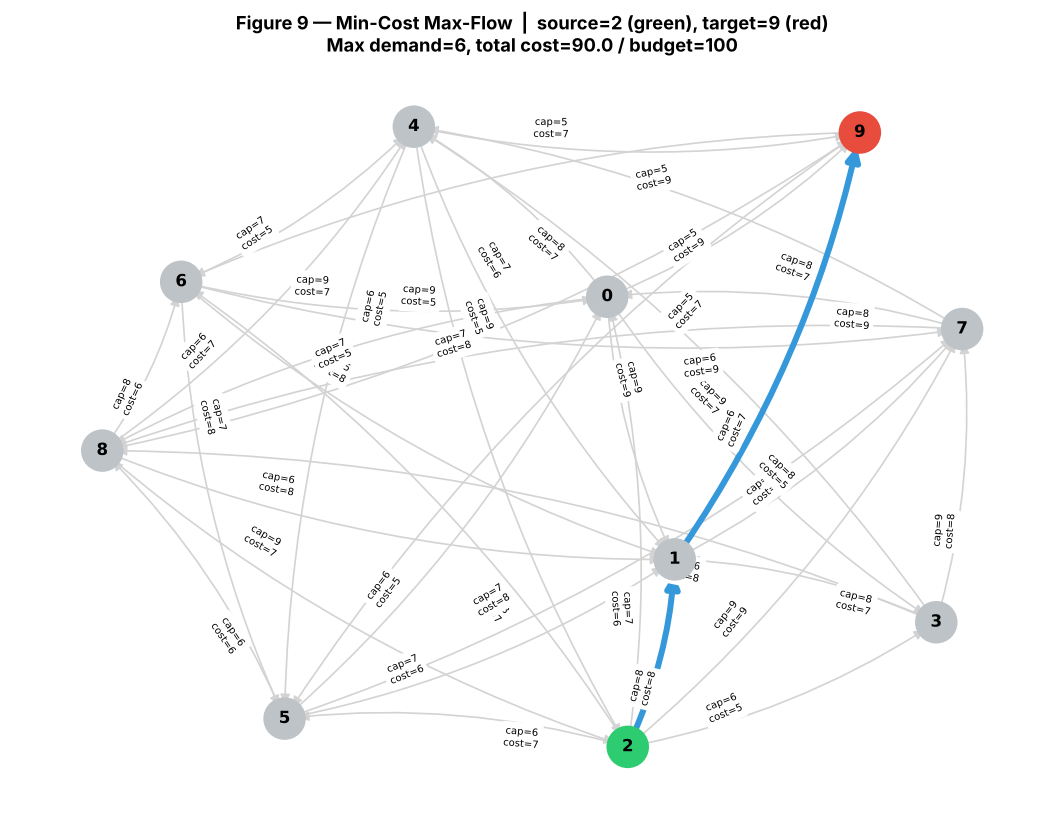

In [18]:
# ── Visualise the flow network ────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 7))
pos = nx.spring_layout(G_flow, seed=SEED)

# All edges in light grey
nx.draw_networkx_edges(G_flow, pos, ax=ax,
                       edge_color="lightgrey", arrows=True,
                       arrowsize=12, width=1.0,
                       connectionstyle="arc3,rad=0.1")

# Flow-carrying edges in blue, width proportional to flow
if best_flow:
    flow_edges  = [(u, v) for u in best_flow for v in best_flow[u] if best_flow[u][v] > 0]
    flow_widths = [best_flow[u][v] * 0.6 for u, v in flow_edges]
    nx.draw_networkx_edges(G_flow, pos, edgelist=flow_edges, ax=ax,
                           edge_color="#3498db", width=flow_widths,
                           arrows=True, arrowsize=16,
                           connectionstyle="arc3,rad=0.1")

# Node colours: source=green, target=red, others=grey
node_colours = []
for n in G_flow.nodes():
    if n == source:   node_colours.append("#2ecc71")
    elif n == target: node_colours.append("#e74c3c")
    else:             node_colours.append("#bdc3c7")

nx.draw_networkx_nodes(G_flow, pos, node_color=node_colours, node_size=600, ax=ax)
nx.draw_networkx_labels(G_flow, pos, ax=ax, font_size=10, font_weight="bold")

# Edge labels: capacity/cost
edge_labels = {(u, v): f"cap={G_flow[u][v]['capacity']}\ncost={G_flow[u][v]['weight']}"
               for u, v in G_flow.edges()}
nx.draw_networkx_edge_labels(G_flow, pos, edge_labels=edge_labels,
                             font_size=6, ax=ax, label_pos=0.3)

ax.set_title(
    f"Figure 9 — Min-Cost Max-Flow  |  source={source} (green), target={target} (red)\n"
    f"Max demand={max_demand}, total cost={best_cost:.1f} / budget={BUDGET}",
    fontweight="bold", fontsize=11
)
ax.axis("off")
plt.tight_layout()
plt.savefig("fig9_min_cost_flow.png", bbox_inches="tight")
plt.show()


**Method:** NetworkX's `min_cost_flow` uses the network simplex algorithm, which finds the minimum-cost feasible flow for a given demand. Demand is increased from 1 until the total cost would exceed the budget. A linear scan is fine here because the network has only 10 nodes.

**Result:** the maximum demand deliverable within the budget of 100 is **6 units, at a total cost of 90**. All of the flow uses the two-step route 2 → 1 → 9. The 1 → 9 edge is at full capacity (6), so it is the bottleneck: sending a 7th unit would require a more expensive route that breaks the budget. Blue edges carry flow, with width proportional to flow volume.

---
## References

- Barabási, A.-L. (2016). *Network Science*. Cambridge University Press. [networksciencebook.com](http://networksciencebook.com)
- Leskovec, J., Huttenlocher, D. & Kleinberg, J. (2010). Signed networks in social media. *CHI 2010*. *(Wikipedia Vote dataset)*
- Girvan, M. & Newman, M.E.J. (2002). Community structure in social and biological networks. *PNAS*, 99(12), 7821–7826.
- Ford, L.R. Jr. & Fulkerson, D.R. (1962). *Flows in Networks*. Princeton University Press.
- Erdős, P. & Rényi, A. (1960). On the evolution of random graphs. *Publ. Math. Inst. Hung. Acad. Sci.*, 5, 17–61.
- NetworkX Developers (2023). *NetworkX Documentation*. [networkx.org](https://networkx.org/documentation/stable/)
- SciPy Community (2023). *SciPy Documentation*. [scipy.org](https://scipy.org)
- OpenAI (2024). ChatGPT (GPT-4). Response to query on average distance in disconnected networks. *(Referenced in Part 2c)*
